# Окупаемость высшего образования в условиях деактуализации навыков в IT-индустрии

## Динамика доходов и обесценение навыков на российском рынке труда по данным РМЭЗ-НИУ ВШЭ (2016–2025 гг.)
## Информация об исследовании и справка

### Об исследовании
Настоящее исследование представляет собой приложение к оригинальной работе Ильясов Р., Максимкина В., Пупышев В., Коротчик Я., Григорьев А. Окупаемость высшего образования в условиях деактуализации навыков в IT-индустрии, в котором проводится статистический анализ с целью проверки предложенной в статье экономической модели и определения её параметров на российских данных.

### Авторы
Ильясов Ролан

Максимкина Виктория

Пупышев Вячеслав

Коротчик Ярослав

Григорьев Александр

# Источники данных
Исследования РМЭЗ-НИУ ВШЭ, волны 25—34, данные по индивидам.

https://www.hse.ru/rlms/spss

## Эконометрическая спецификация и модель

В настоящем исследование с данными сопоставляется уравнение:

$$\ln(earn)_{it} = \alpha_{it} + \sum_{a=1}^{A} \beta_a a_{it} + \sum_{a=1}^{A} \gamma_a \left(a_{it} \times \overline{SkillChange_O^M}\right) + \delta X_{it} + \theta_t + \epsilon_{it}$$

### Эконометрическая идентифицируемость и предпосылки модели:
- **Индивидуальная гетерогенность ($\alpha_{it}$):** В спецификации Pooled OLS выражается константой $\alpha$. В модели Panel FE выступает индивидуальным фиксированным эффектом $\alpha_i$, поглощающим неизменные во времени ненаблюдаемые характеристики работника (врожденный когнитивный уровень $IQ$, базовая трудовая мотивация, социальное происхождение).
- **Вектор когорт ($\sum \beta_a a_{it}$):** Набор бинарных индикаторов принадлежит ли работник $i$ в момент $t$ к одной из 6 возрастных групп. Коэффициенты $\beta_a$ оценивают базовую траекторию дохода в консервативных отраслях со стабильной технологической базой ($SkillChange = 0$).
- **Кросс-эффект взаимодействия ($\sum \gamma_a [a_{it} \times \overline{SkillChange_O^M}]$):** Центральный параметр исследования. Показывает дифференциальное изменение отдачи от возраста при увеличении показателя технологической нестабильности в профессии на 1 стандартное отклонение.
- **Кластеризация стандартных ошибок:** Ввиду того, что переменная $SkillChange$ агрегирована на уровне профессиональных кодов ISCO-08, стандартные ошибки $SE$ кластеризуются на уровне профессий ($CRV1\ Cluster\ Robust\ Standard\ Errors$) для предотвращения проблемы Moulton (1986).

## Операционализация переменных и паспорт кодификатора РМЭЗ-НИУ ВШЭ

В таблице ниже приведена полная процедура трансформации первичных переменных опроса RLMS-HSE в эконометрические показатели регрессионной модели:

| Название в модели | Источник в РМЭЗ | Формулировка вопроса / Алгоритм построения | Экономический смысл и роль в модели |
| :--- | :--- | :--- | :--- |
| **`ln_earn`** | `j10`, `j6.2`, `cpi` | $\ln \left[ \frac{j10 \times cpi_{year}}{j6.2 \times 4.33} \right]$. Удалены коды `99999997` и нули. Триммирование 1% и 99% перцентилей. | Зависимая переменная: Натуральный логарифм реальной почасовой оплаты труда по основному месту работы (в ценах 2025 г.). |
| **`age_group`** | `age` (`_age`) | Группировка возраста на когорты: 20–24 (референтная), 25–29, 30–34, 35–39, 40–44, 45–49, 50–60 лет. | Репрезентация жизненного цикла работника и потенциального трудового стажа. |
| **`SkillChange_norm`**| `j1.1.8`, `j2cod08` | Процент ответивших «не удовлетворен соответствием работы квалификации» (коды 4-5 в `j1.1.8`), усредненный по 4-значным кодам ISCO-08 и нормированный в Z-score. | Прокси-показатель скорости изменения требований к знаниям и деактуализации базового образования в профессии. |
| **`higher_educ`** | `diplom` (`_diplom`)| Бинарный флаг: `1` — наличие диплома ВУЗа (код 6 в `diplom`), `0` — среднее или среднее специальное образование. | Контроль накопленного формального человеческого капитала (премия за диплом). |
| **`tenure`** | `j5a` (`_j5a`) | Годы непрерывной работы на текущем предприятии. Очищено от отрицательных значений и нонсенсов (>50 лет). | Контроль накопленного *специфического* человеческого капитала на конкретном рабочем месте. |
| **`gender`** | `h5` (`_h5`) | Бинарный флаг: `1` — мужской пол, `2` — женский пол. | Контроль гендерной дискриминации и различий в структуре занятости. |
| **`status`** | `status` | Категориальная переменная: 1 — областной центр, 2 — город, 3 — ПГТ, 4 — село. | Контроль пространственной неоднородности и плотности локальных рынков труда. |
| **`is_it_prof`** | `j2cod08` | Бинарный флаг для кодов ISCO-08: 2511–2519 (разработчики ПО), 2521–2529 (сети/БД), 3511–3514 (ИКТ-техники), 1330 (IT-менеджеры). | Идентификация ядра ячеек ИКТ и STEM-сектора для построения графиков траекторий. |

In [1]:
import os
import sys
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
sys.path.append(os.path.abspath('..'))

from src.data_loader import load_all_waves
from src.feature_engineering import prepare_econometric_dataset
from src.models import run_pooled_ols, run_panel_fe, get_model_summary_table
from src.visualization import (
    plot_skill_change_coefficients,
    plot_age_wage_trajectories,
    plot_skill_change_distribution
)

print('[Initialization] Окружение и аналитические модули успешно подключены.')

[Initialization] Окружение и аналитические модули успешно подключены.


## Первичная загрузка и очистка панельного массива РМЭЗ-НИУ ВШЭ (2016–2025 гг.)

Загружаем 10 последовательных волн опроса ($R25$ — $R34$), проверяем целостность идентификаторов `idind` и проводим очистку данных в соответствии с методологическими фильтрами.

In [2]:
# Загрузка исходных микроданных за 10 лет
raw_data = load_all_waves(data_dir='../data')

# Выполнение процедур очистки, дефлирования и расчёта Z-индекса SkillChange
df_model, cohort_cols, interaction_cols = prepare_econometric_dataset(raw_data)

# 3. Вывод паспорта полученной исследовательской выборки
print(f"\n[Sample Info] Общий объем выборки: N = {len(df_model)} наблюдений.")
print(f"[Sample Info] Количество уникальных респондентов в панели: {df_model['idind'].nunique()}.")
print(f"[Sample Info] Средняя продолжительность наблюдения за респондентом: {len(df_model)/df_model['idind'].nunique():.2f} года.")

df_model[['hourly_wage', 'ln_earn', 'age', 'tenure', 'SkillChange_norm']].describe().T

[DataLoader] Волна r34 (2025 г.): загружено 16176 строк.
[DataLoader] Волна r33 (2024 г.): загружено 16882 строк.
[DataLoader] Волна r32 (2023 г.): загружено 17011 строк.
[DataLoader] Волна r31 (2022 г.): загружено 17342 строк.
[DataLoader] Волна r30 (2021 г.): загружено 17605 строк.
[DataLoader] Волна r29 (2020 г.): загружено 17701 строк.
[DataLoader] Волна r28 (2019 г.): загружено 18060 строк.
[DataLoader] Волна r27 (2018 г.): загружено 18234 строк.
[DataLoader] Волна r26 (2017 г.): загружено 18953 строк.
[DataLoader] Волна r25 (2016 г.): загружено 18756 строк.
[DataLoader] Успешно объединено 176720 наблюдений за 10 волн.
[FeatureEng] Выборка готова к оцениванию: 60527 наблюдений (13674 уникальных индивидов).

[Sample Info] Общий объем выборки: N = 60527 наблюдений.
[Sample Info] Количество уникальных респондентов в панели: 13674.
[Sample Info] Средняя продолжительность наблюдения за респондентом: 4.43 года.


,count,mean,std,min,25%,50%,75%,max
hourly_wage,60527.0,238.413938,144.340551,39.793924,136.515268,202.078522,298.306390,951.501155
ln_earn,60527.0,5.310855,0.573637,3.683714,4.916436,5.308656,5.698121,6.858041
age,60527.0,40.637691,10.179942,20.000000,33.000000,40.500000,48.500000,60.000000
tenure,60527.0,7.959440,8.220324,0.000000,2.000000,5.000000,12.000000,45.000000
SkillChange_norm,60527.0,-0.000860,0.999619,-1.369788,-0.733231,-0.169326,0.481632,26.766034


## Описательный анализ распределения индекса SkillChange

Вариация сконструированного индекса деактуализации навыков по укрупненным профессиональным группам классификатора ISCO-08.

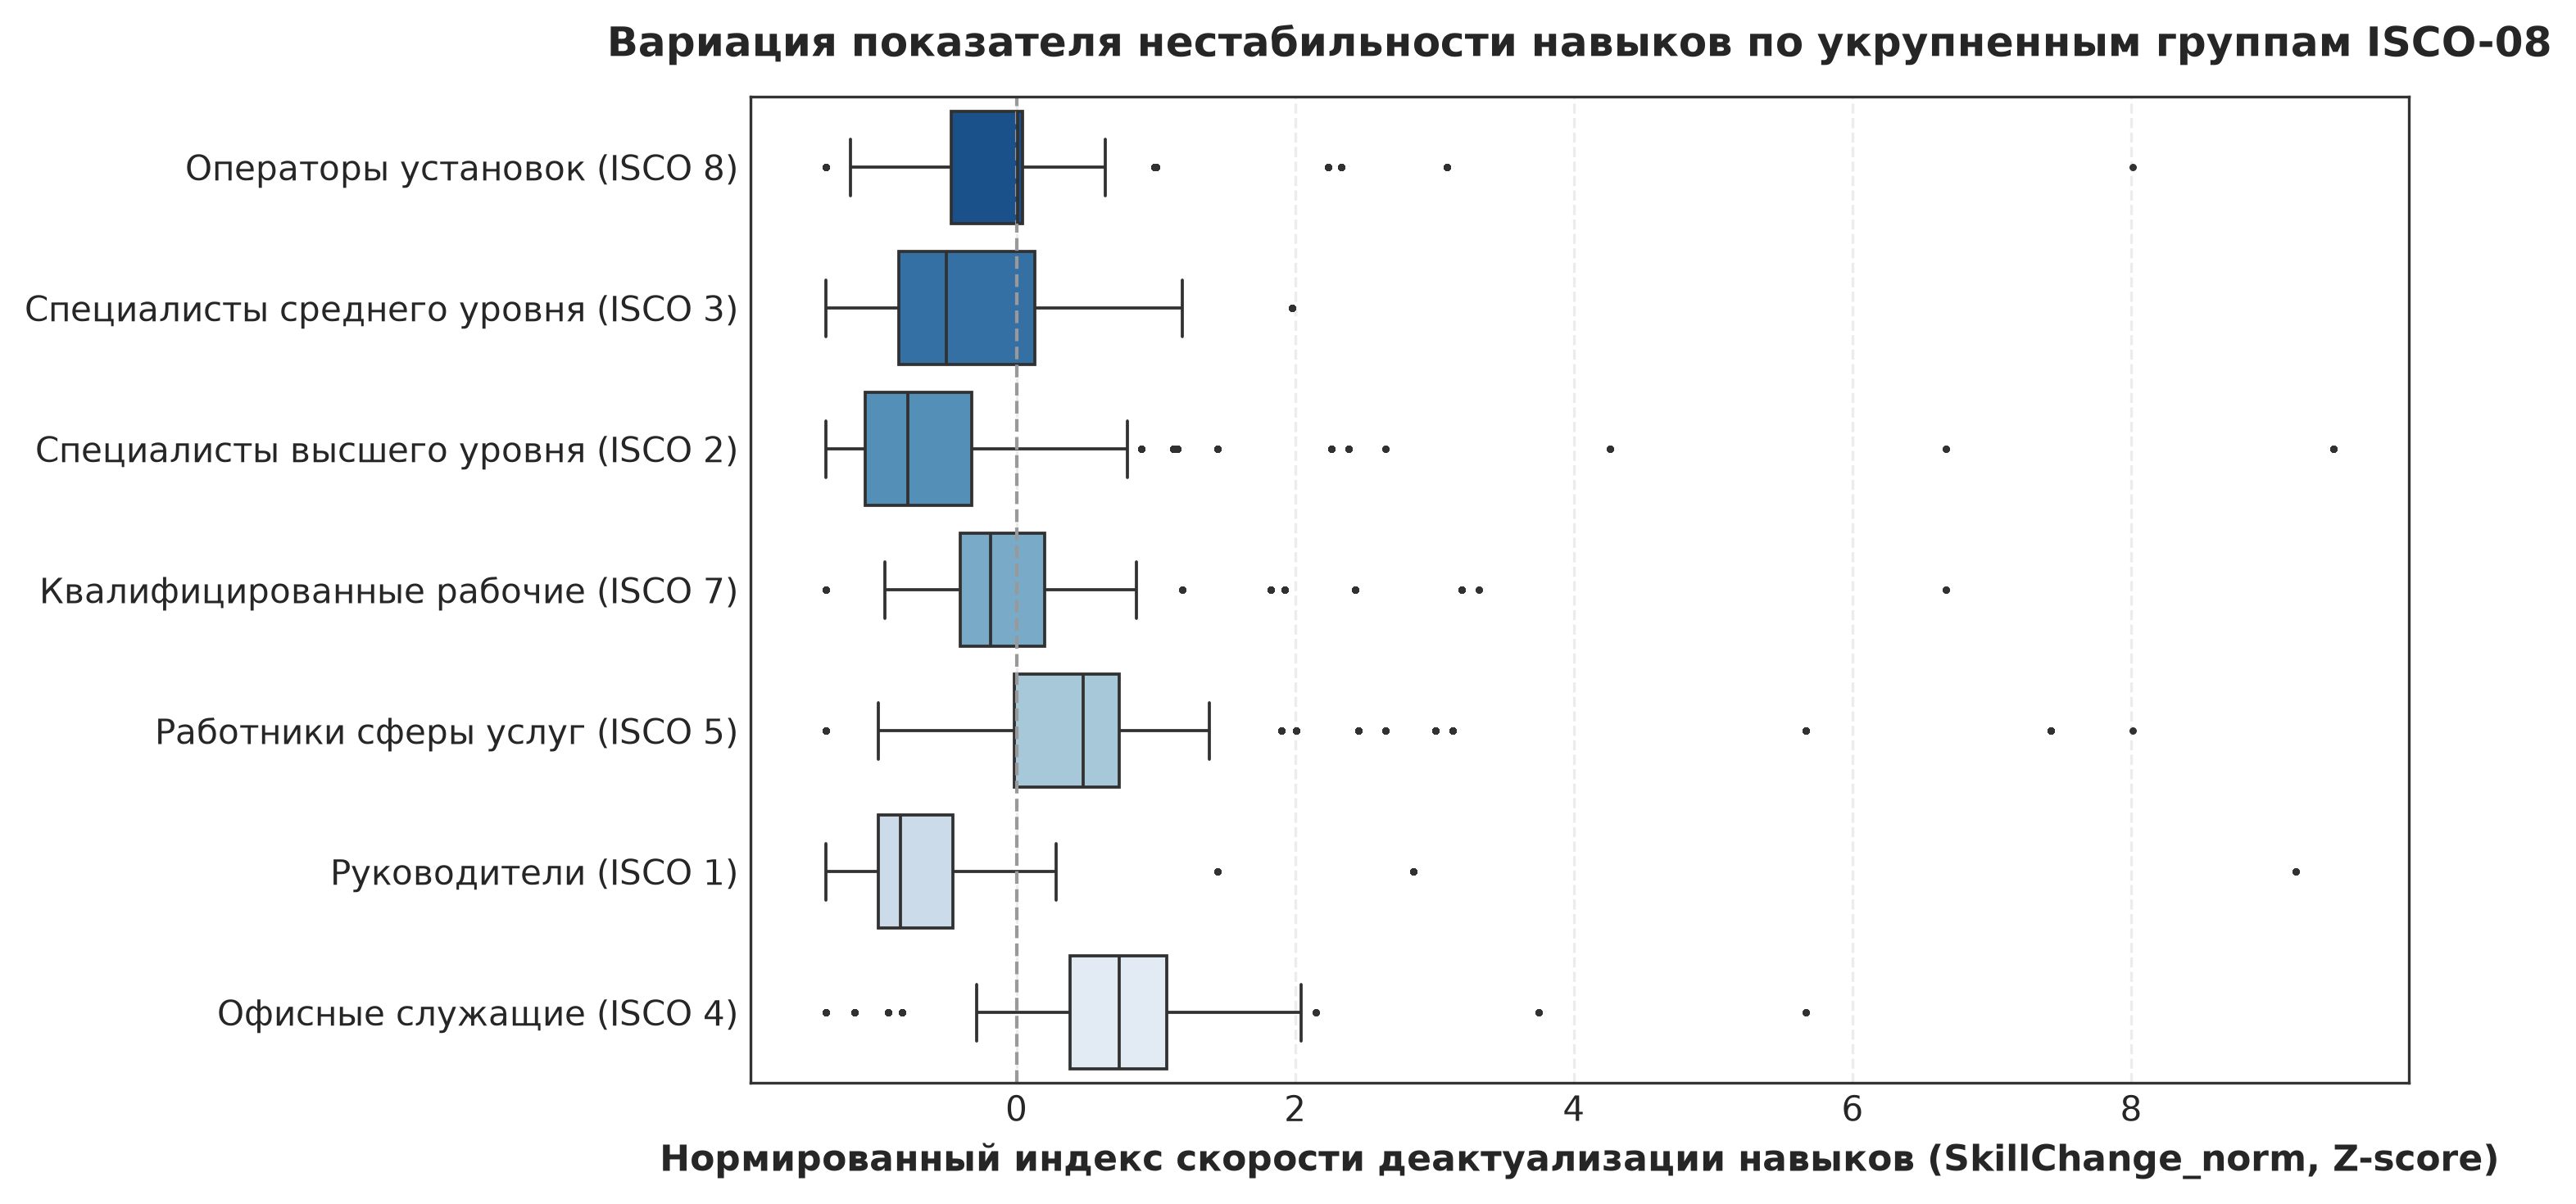

In [3]:
# Построение распределения индекса SkillChange по группам ISCO-08
fig_dist, ax_dist = plot_skill_change_distribution(df_model)
plt.show()

## Оценивание эконометрических моделей (Pooled OLS vs. Panel FE)

Результаты двух спецификаций:
1. **Pooled OLS:** Модель межгруппового среза с кластеризацией ошибок по профессиям ($ISCO-08$).
2. **Panel FE:** Панельная модель с фиксированными эффектами индивида и года, удаляющая ненаблюдаемую способность ($IQ$, базовый когнитивный капитал).

In [4]:
print("[Estimation 1/2] Запуск Pooled OLS (Cluster-robust SE by ISCO-08)... formulation...")
model_ols = run_pooled_ols(df_model, cohort_cols, interaction_cols)

print("[Estimation 2/2] Запуск Panel FE (Entity & Time Fixed Effects)... formulation...")
model_fe = run_panel_fe(df_model, cohort_cols, interaction_cols)

# Формирование сводной таблицы коэффициентов
summary_table = get_model_summary_table(model_ols, model_fe, cohort_cols, interaction_cols)
summary_table

[Estimation 1/2] Запуск Pooled OLS (Cluster-robust SE by ISCO-08)... formulation...
[Estimation 2/2] Запуск Panel FE (Entity & Time Fixed Effects)... formulation...


,Variable,OLS_Coef,OLS_SE,OLS_PValue,FE_Coef,FE_SE,FE_PValue
0,age_25_29,0.024000,0.012434,5.359134e-02,0.117906,0.014857,2.133566e-15
1,age_30_34,0.052642,0.015355,6.072889e-04,0.156027,0.019765,2.987190e-15
2,age_35_39,0.076980,0.017101,6.749365e-06,0.178506,0.023350,2.130893e-14
3,age_40_44,0.072718,0.019409,1.792247e-04,0.204123,0.026661,1.951365e-14
4,age_45_49,0.054945,0.020878,8.495884e-03,0.209759,0.030473,5.915961e-12
5,age_50_60,-0.010135,0.025368,6.895232e-01,0.193905,0.034327,1.624776e-08
6,age_25_29_x_SkillChange,-0.005509,0.010628,6.042370e-01,-0.024644,0.008332,3.100148e-03
7,age_30_34_x_SkillChange,-0.033825,0.012622,7.364937e-03,-0.036861,0.007549,1.049273e-06
8,age_35_39_x_SkillChange,-0.018890,0.013569,1.638847e-01,-0.022811,0.007233,1.612778e-03
9,age_40_44_x_SkillChange,-0.037936,0.014215,7.613529e-03,-0.022533,0.006710,7.849710e-04


## Визуализация оценок моделей

Графики с доверительными интервалами (95% CI) для оценки штрафов по возрастам

Сравнение фактической траектории реальных почасовых ставок.

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


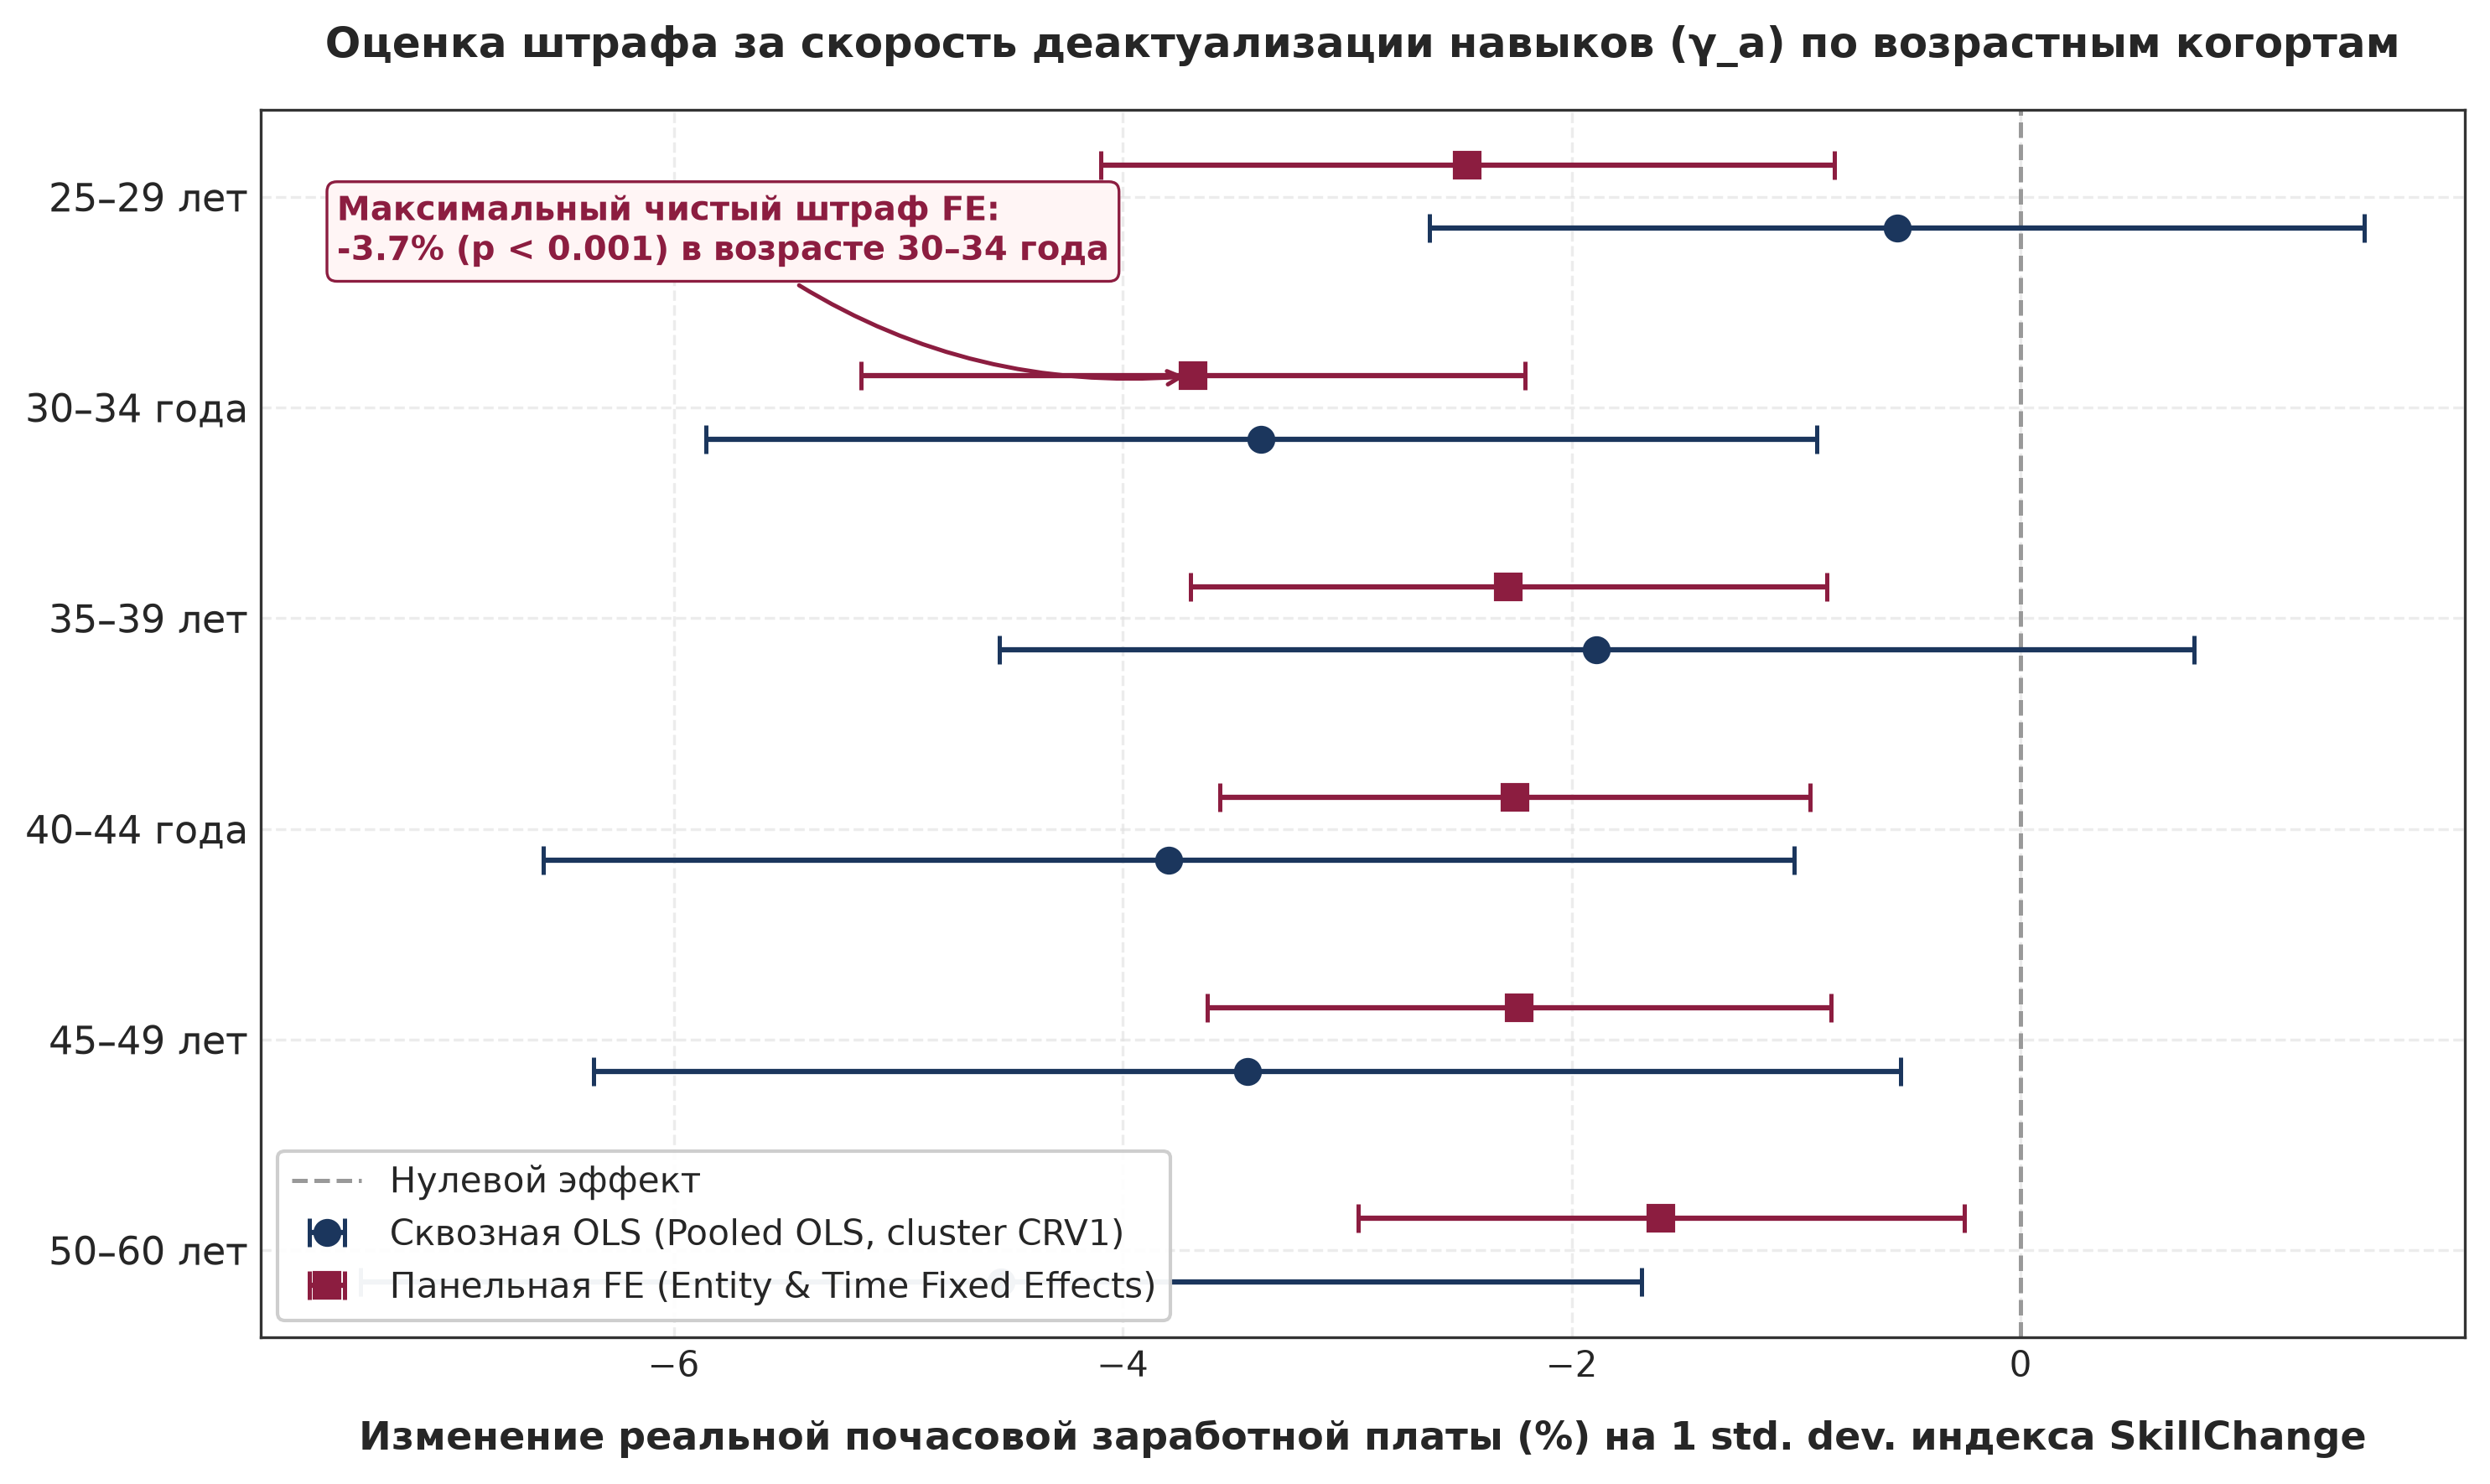

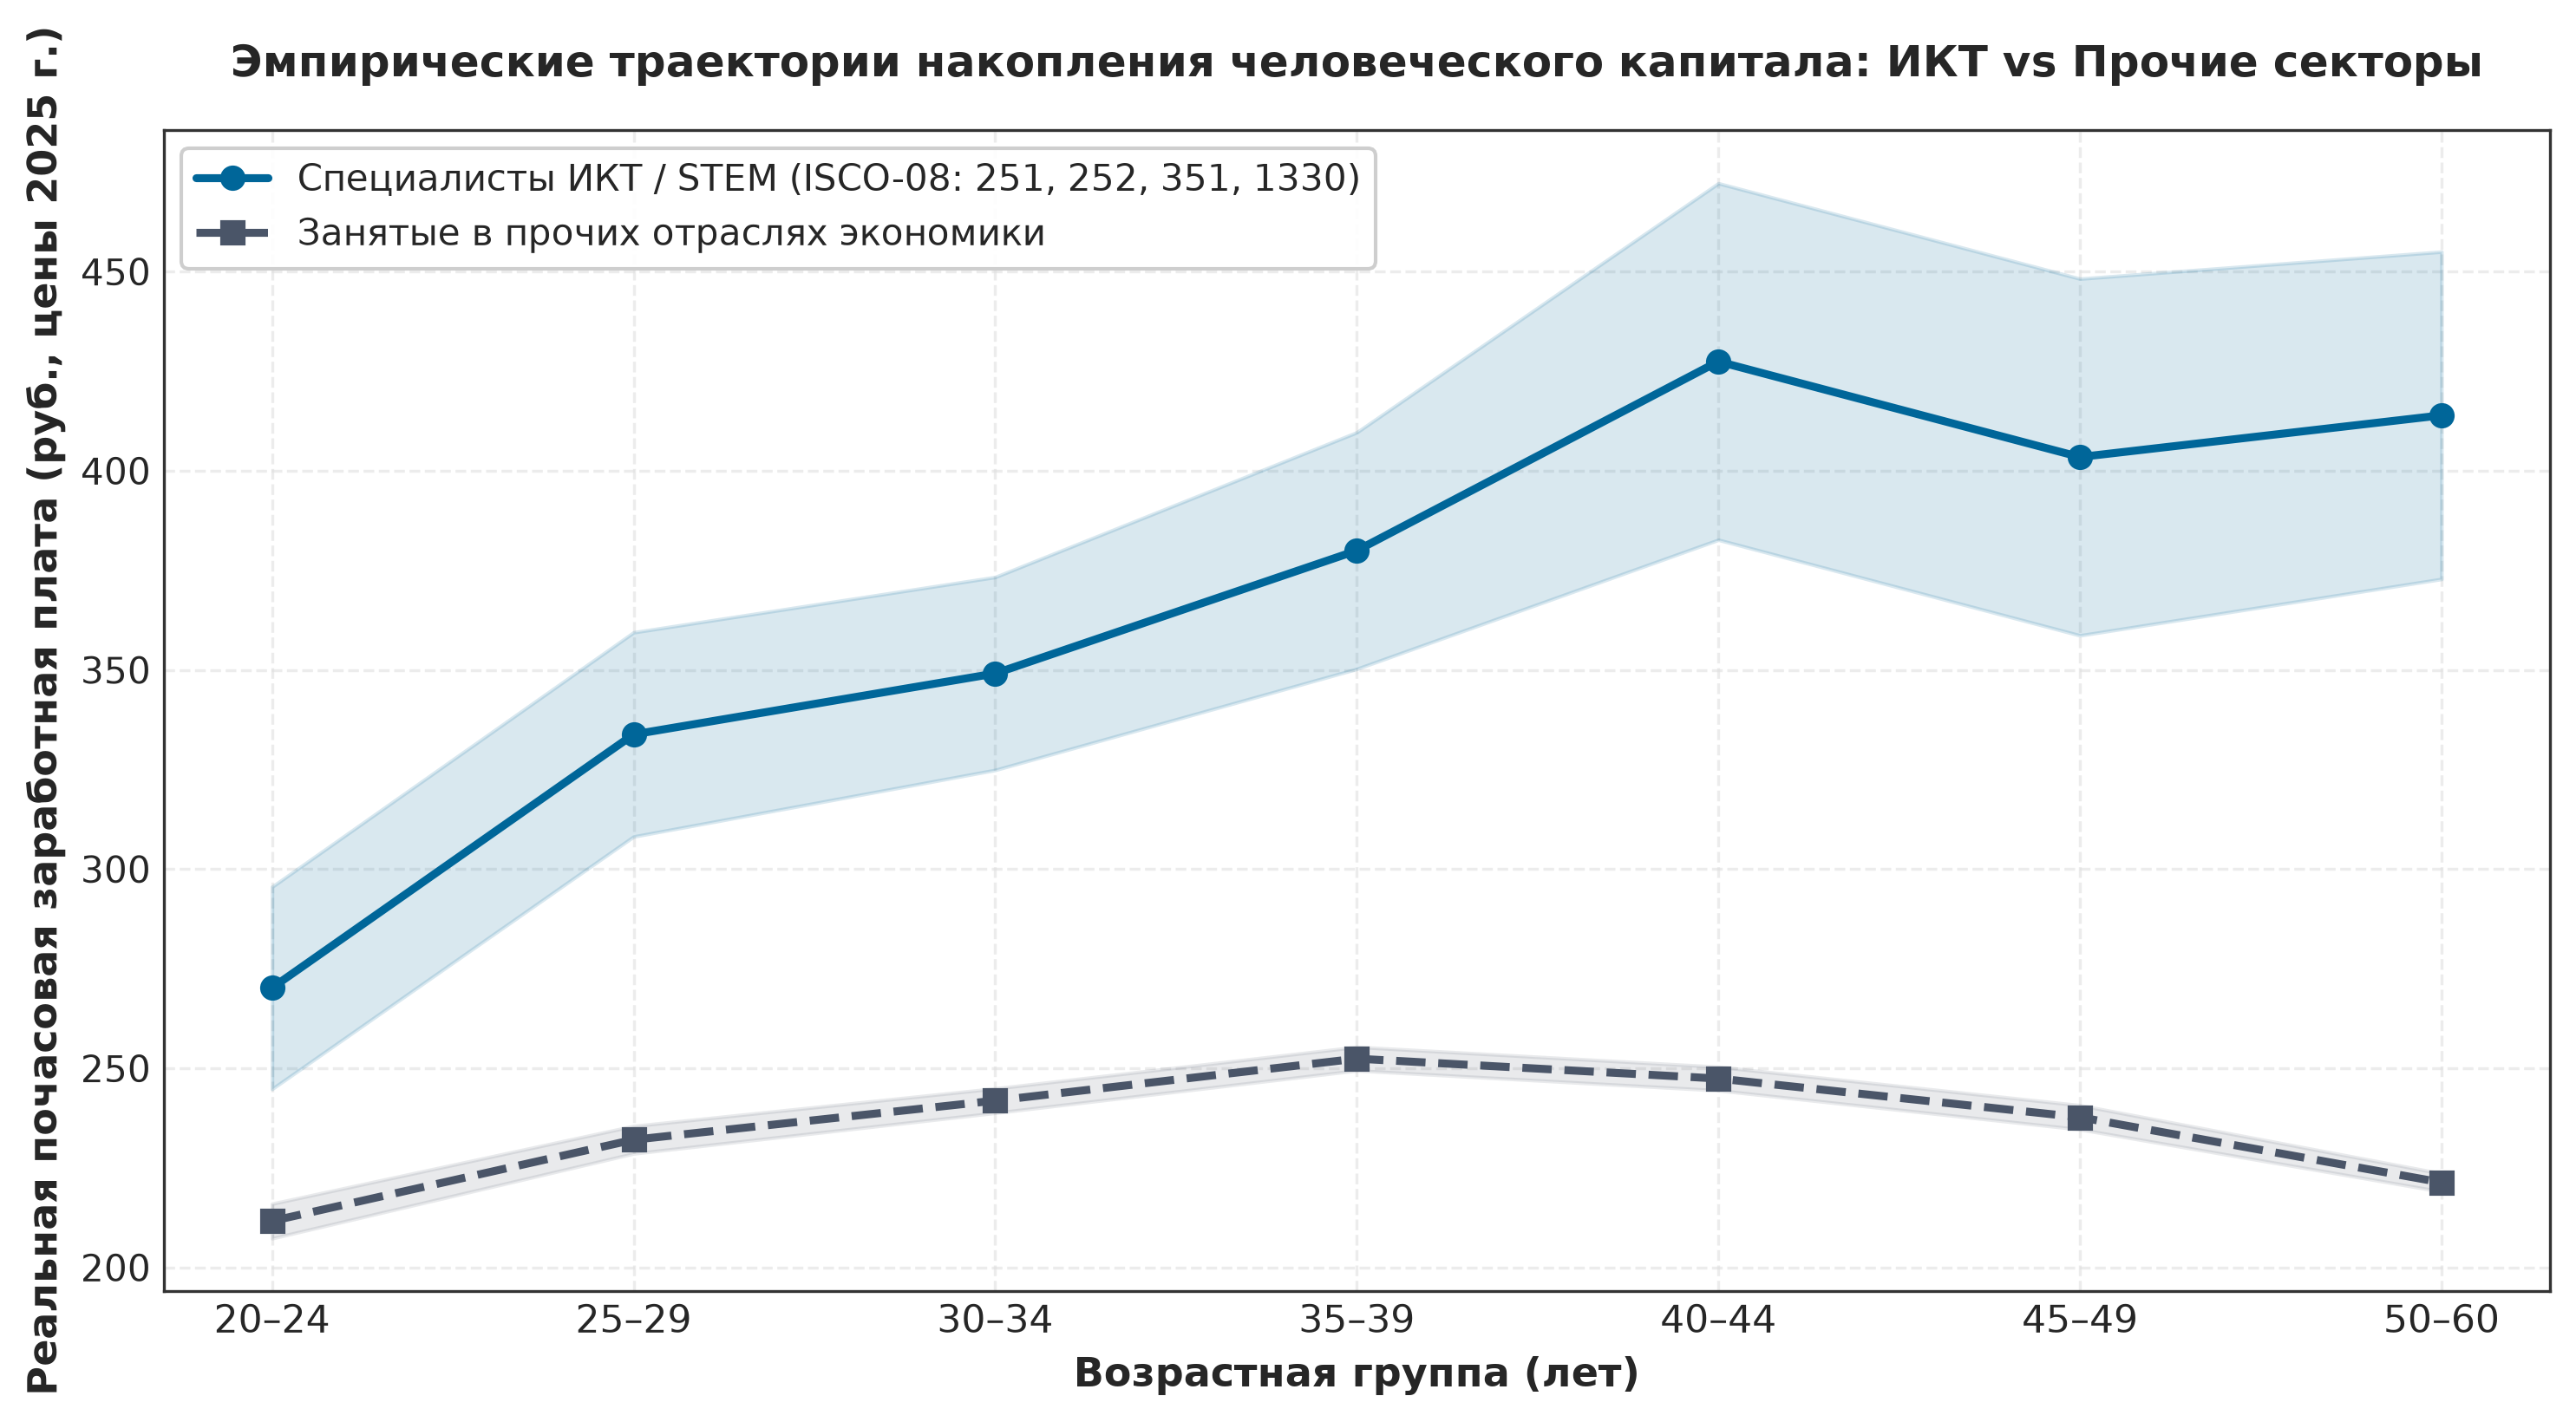

In [5]:
# 1. График коэффициентов штрафа за деактуализацию навыков с 95% CI
fig_coef, ax_coef = plot_skill_change_coefficients(summary_table)

# 2. Траектории зарплат: ИКТ/STEM vs Прочие секторы с интервальными лентами
fig_traj, ax_traj = plot_age_wage_trajectories(df_model)

plt.show()